# MUSIC subject-info 구조 확인
임상 데이터만 사용. 파형은 쓰지 않는다.

> **탐색용 노트북.** 데이터 구조 확인과 전처리 결정의 근거를 기록한다.
> 최종 전처리, 모델, SHAP은 `02_label_sensitivity.ipynb`를 기준으로 한다.
> 이 노트북의 AutoML/SHAP 결과는 PSVT 9를 결측으로 처리한 이전 버전이다.

In [1]:
from pathlib import Path
import pandas as pd

pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 80)

# 노트북 위치와 상관없이 ~/poc 를 루트로 잡는다
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "music"
print("ROOT:", ROOT)
print(sorted(p.name for p in DATA.iterdir()))

ROOT: /home/mingyu/poc-test
['RECORDS', 'subject-info.csv', 'subject-info_codes.csv', 'subject-info_definitions.csv']


In [2]:
# 이 파일은 세미콜론 구분 + 소수점 쉼표 형식이다
na = ["#VALUE!", "#value", "#N/A", "NA", ""]
df = pd.read_csv(DATA / "subject-info.csv", sep=";", decimal=",", na_values=na)

# definitions/codes는 스페인어 문자가 있어서 latin-1로 읽는다 (utf-8이면 에러)
defs = pd.read_csv(DATA / "subject-info_definitions.csv", sep=";", encoding="latin-1")
codes = pd.read_csv(DATA / "subject-info_codes.csv", sep=";", encoding="latin-1")
print("shape:", df.shape)
print("definitions:", defs.shape, "| codes:", codes.shape)

shape: (992, 103)
definitions: (15, 3) | codes: (80, 4)


In [3]:
defs

,Variable,Column,Definition
0,NYHA class,K,New York Heart Association classs
1,ALT o GPT (IU/L),AB,Alanine Aminotransferase or Glutamic Pyruvic Transaminase
2,AST o GOT (IU/L),AC,Aspartate Aminotransferase or Glutamyl oxaloacetic transaminase
3,HDL (mmol/L),AJ,High-density lipoprotein cholesterol
4,LDL (mmol/L),AL,Low Density Lipoprotein Cholesterol
5,Pro-BNP (ng/L),AN,pro b-type natriuretic peptide
6,T3 (pg/dL),AP,Triiodothyronine
7,T4 (ng/L),AQ,Thyroxine
8,TSH (mIU/L),AS,Thyroid Stimulating Hormone
9,LVEF (%),AZ,Left Ventricular Ejection Fraction


In [4]:
codes

,Variable,Column,Notes,Codes
0,Exit of the study,D,Cause of exit from the study,0: survivor;
1,NaN,NaN,NaN,1: lost to follow-up;
2,NaN,NaN,NaN,2: cardiac transplantation;
3,NaN,NaN,NaN,3: Death;
4,NaN,NaN,NaN,According to closing date of the study
5,Cause of death,E,Cause of death,0: survivor;
6,NaN,NaN,NaN,1: non-cardiac death;
7,NaN,NaN,NaN,3: SCD;
8,NaN,NaN,NaN,6-7: Pump-failure death;
9,NaN,NaN,NaN,According to closing date of the study


In [5]:
exit_col, cod_col = "Exit of the study", "Cause of death"
print(pd.crosstab(df[exit_col].fillna(-1), df[cod_col].fillna(-1), margins=True))

Cause of death       0   1   3    6   7  All
Exit of the study                           
-1.0               695   0   0    0   0  695
 1.0                11   0   0    0   0   11
 2.0                20   0   0    0   0   20
 3.0                 0  61  94  100  11  266
 All               726  61  94  100  11  992


In [6]:
exit_col, cod_col = "Exit of the study", "Cause of death"
base = df.loc[~df[exit_col].isin([1, 2])].copy()
base["label_scd"] = (base[cod_col] == 3).astype(int)

age_na = base["Age"].isna()
print("나이 결측:", age_na.sum(), "/", len(base))
print("나이 최솟값/최댓값(결측 제외):", base["Age"].min(), "/", base["Age"].max())
print("나이 상위 8개:", base["Age"].sort_values(ascending=False).head(8).tolist())

print("\n나이 결측 환자의 라벨(SCD=1):")
print(base.loc[age_na, "label_scd"].value_counts())
print("\n나이 결측 환자의 Cause of death:")
print(base.loc[age_na, cod_col].value_counts(dropna=False))

나이 결측: 0 / 961
나이 최솟값/최댓값(결측 제외): 20 / >89
나이 상위 8개: ['>89', '89', '88', '87', '86', '86', '86', '85']

나이 결측 환자의 라벨(SCD=1):
Series([], Name: count, dtype: int64)

나이 결측 환자의 Cause of death:
Series([], Name: count, dtype: int64)


In [7]:
age_str = base["Age"].astype(str).str.strip()
is_gt89 = age_str == ">89"
print(">89 환자:", is_gt89.sum(), "/", len(base))
print(">89 환자의 SCD:", base.loc[is_gt89, "label_scd"].sum())

# 숫자 컬럼이어야 하는데 문자열이 섞인 컬럼 전부 스캔
for c in base.select_dtypes(include="object").columns:
    num = pd.to_numeric(base[c], errors="coerce")
    bad = base.loc[num.isna() & base[c].notna(), c]
    if len(bad):
        print(f"{c} | 숫자 아닌 값 {len(bad)}개 | 예:", bad.value_counts().head(5).to_dict())

>89 환자: 1 / 961
>89 환자의 SCD: 0
Patient ID | 숫자 아닌 값 961개 | 예: {'P0001': 1, 'P0002': 1, 'P0003': 1, 'P0004': 1, 'P0005': 1}
Age | 숫자 아닌 값 1개 | 예: {'>89': 1}
Holter onset (hh:mm:ss) | 숫자 아닌 값 634개 | 예: {"'10:32:49'": 2, "'10:10:44'": 2, "'8:19:11'": 2, "'9:41:56'": 2, "'10:28:31'": 2}
Number of ventricular premature contractions per hour | 숫자 아닌 값 312개 | 예: {'4,583,333,333': 6, '2,041,666,667': 3, '3,541,666,667': 3, '6,166,666,667': 3, '4,166,666,667': 3}


In [8]:
base = base.loc[~is_gt89].copy()
base["Age"] = pd.to_numeric(base["Age"])   # 이제 전부 숫자라 변환된다
print("환자:", len(base), "| SCD:", base["label_scd"].sum(), "| Age dtype:", base["Age"].dtype)

환자: 960 | SCD: 94 | Age dtype: int64


In [9]:
import numpy as np
fu = [c for c in base.columns if c.startswith("Follow-up")][0]

# 라벨별 추적 기간: SCD 환자가 짧으면 누수가 맞다
print(base.groupby("label_scd")[fu].describe()[["count", "mean", "50%", "min", "max"]])

# days_4years가 추적 기간을 1460일로 자른 값인지 확인 (1.0에 가까우면 맞다)
print("days_4years == min(추적기간, 1460):",
      (base["days_4years"] == np.minimum(base[fu], 1460)).mean())

           count         mean     50%   min     max
label_scd                                          
0          866.0  1631.334873  1833.0  46.0  2065.0
1           94.0   561.776596   479.5  33.0  1726.0
days_4years == min(추적기간, 1460): 1.0


In [10]:
def col_letter(i):
    s, i = "", i + 1
    while i:
        i, r = divmod(i - 1, 26)
        s = chr(65 + r) + s
    return s

letters = {c: col_letter(i) for i, c in enumerate(df.columns)}   # 원본 열 글자(definitions/codes의 Column과 대조용)

rows = []
for c in base.columns:
    s = pd.to_numeric(base[c], errors="coerce")
    n999 = int((s == 999).sum())
    if n999:
        rest = s[s != 999]
        rows.append({
            "column": c, "letter": letters[c], "n_999": n999,
            "missing_%": round(base[c].isna().mean() * 100, 1),
            "min_wo999": rest.min(), "max_wo999": rest.max(),
            "n_unique": s.nunique(),
        })
pd.DataFrame(rows).sort_values("n_999", ascending=False)

,column,letter,n_999,missing_%,min_wo999,max_wo999,n_unique
0,PR interval (ms),BJ,268,0.0,86.0,300.0,122
1,Number of supraventricular premature beats in 24h,CE,253,6.1,0.0,17000.0,237


In [11]:
rhythm_cols = [c for c in base.columns if "rhythm" in c.lower()]
print(rhythm_cols)

pr999 = pd.to_numeric(base["PR interval (ms)"], errors="coerce") == 999
sv999 = pd.to_numeric(base["Number of supraventricular premature beats in 24h"], errors="coerce") == 999

for rc in rhythm_cols:
    print("\n==", rc)
    print(pd.crosstab(base[rc], pr999, margins=True))      # PR=999가 특정 리듬에 몰리나
    print(pd.crosstab(base[rc], sv999, margins=True))

print("PR=999 & SVPB=999 동시:", (pr999 & sv999).sum())
print("SCD 비율 | PR=999:", base.loc[pr999, "label_scd"].mean().round(3),
      "| 아님:", base.loc[~pr999, "label_scd"].mean().round(3))

['ECG rhythm ', 'Holter  rhythm ', 'Paroxysmal supraventricular tachyarrhythmia']

== ECG rhythm 
PR interval (ms)  False  True  All
ECG rhythm                        
0                   685     0  685
1                     2   174  176
2                     0     7    7
3                     5    87   92
All                 692   268  960
Number of supraventricular premature beats in 24h  False  True  All
ECG rhythm                                                         
0                                                    674    11  685
1                                                     17   159  176
2                                                      2     5    7
3                                                     14    78   92
All                                                  707   253  960

== Holter  rhythm 
PR interval (ms)  False  True  All
Holter  rhythm                    
0.0                 626     9  635
1.0                   4   160  164
2.0                  

In [12]:
fu = [c for c in base.columns if c.startswith("Follow-up")][0]

# 누수(결과 정보) + ID + 결측 많은 컬럼 + 문자열 시각 컬럼
drop_cols = ["Patient ID", "Exit of the study", "Cause of death", fu, "days_4years",
             "Holter onset (hh:mm:ss)"]
drop_cols += [c for c in base.columns if "Longest RR" in c]

y = base["label_scd"]
X = base.drop(columns=drop_cols + ["label_scd"])

print(f"입력 컬럼 수: {X.shape[1]}")   # 96개 안팎이면 정상

miss = (X.isna().mean() * 100).round(1).sort_values(ascending=False)
print(miss[miss >= 10].to_string())

입력 컬럼 수: 96
SDNN (ms)                                      40.2
pNN50 (%)                                      40.2
RMSSD (ms)                                     40.2
SDANN (ms)                                     40.2
T3 (pg/dL)                                     37.4
Bradycardia                                    34.8
Normalized Troponin                            16.1
Troponin (ng/mL)                               16.1
Pro-BNP (ng/L)                                 12.1
Right ventricle end-diastolic diameter (mm)    12.0
Left ventricle end-systolic diameter (mm)      11.7
T4 (ng/L)                                      10.9


In [13]:
import numpy as np

for c in ["PR interval (ms)", "Number of supraventricular premature beats in 24h"]:
    base[c] = pd.to_numeric(base[c], errors="coerce").replace(999, np.nan)

X = base.drop(columns=drop_cols + ["label_scd"])   # base를 고쳤으니 X도 다시 만든다
miss = (X.isna().mean() * 100).round(1).sort_values(ascending=False)
print(miss[miss >= 10].to_string())

SDNN (ms)                                            40.2
pNN50 (%)                                            40.2
RMSSD (ms)                                           40.2
SDANN (ms)                                           40.2
T3 (pg/dL)                                           37.4
Bradycardia                                          34.8
Number of supraventricular premature beats in 24h    32.5
PR interval (ms)                                     27.9
Normalized Troponin                                  16.1
Troponin (ng/mL)                                     16.1
Pro-BNP (ng/L)                                       12.1
Right ventricle end-diastolic diameter (mm)          12.0
Left ventricle end-systolic diameter (mm)            11.7
T4 (ng/L)                                            10.9


In [14]:
# 1) 코드표에서 해당 컬럼 설명 찾기
mask = codes.astype(str).apply(
    lambda r: r.str.contains("rhythm|supraventricular", case=False).any(), axis=1)
print(codes[mask].to_string())

# 2) 숫자가 아닌 채로 남은 컬럼 전부 보기
obj = X.select_dtypes(exclude="number").columns.tolist()
print("\n문자열 컬럼:", obj)
for c in obj:
    print(f"\n[{c}]", X[c].nunique(), "unique |", X[c].dropna().astype(str).head(5).tolist())

                                       Variable Column                                          Notes         Codes
44                                  ECG rhythm      BH  Dominant rhythm in 20 min high-resolution ECG  0: Sinusal; 
55                              Holter  rhythm      BT                  Dominant rhythm in Holter ECG  0: Sinusal; 
67  Paroxysmal supraventricular tachyarrhythmia     CF                                            NaN        0: No 

문자열 컬럼: ['Number of ventricular premature contractions per hour']

[Number of ventricular premature contractions per hour] 291 unique | ['112,5', '0', '77,25', '0', '0']


In [15]:
for i in [44, 55, 67]:
    print(codes.loc[i, "Variable"], "->", codes.loc[i, "Codes"])

ECG rhythm  -> 0: Sinusal; 
Holter  rhythm  -> 0: Sinusal; 
Paroxysmal supraventricular tachyarrhythmia -> 0: No 


In [16]:
import re
import numpy as np
import pandas as pd

X = base.drop(columns=drop_cols + ["label_scd"]).copy()
y = base["label_scd"].copy()

# 컬럼명 공백 정리 ("Holter  rhythm " 같은 이중 공백/끝 공백이 H2O에서 헷갈린다)
X.columns = [re.sub(r"\s+", " ", c).strip() for c in X.columns]

def find(key):
    hits = [c for c in X.columns if key.lower() in c.lower()]
    assert len(hits) == 1, (key, hits)   # 여러 개면 어떤 컬럼인지 보고 key를 좁힌다
    return hits[0]

# 1) 센티널 -> NaN (PR, SVPB의 999는 base에서 이미 변환됨. PSVT의 9는 코드표에 정의 없음: 확인 필요)
psvt = find("Paroxysmal supraventricular")
X[psvt] = pd.to_numeric(X[psvt], errors="coerce").replace(9, np.nan)

# 2) 소수점이 쉼표인 문자열 컬럼 -> 숫자
vpc = find("ventricular premature contractions per hour")
na_before = X[vpc].isna().sum()
X[vpc] = pd.to_numeric(X[vpc].astype(str).str.replace(",", ".", regex=False), errors="coerce")
print("VPC/h 결측:", na_before, "->", X[vpc].isna().sum())   # 값이 늘면 변환 실패가 있다는 뜻

# 3) 범주형 코드 -> 문자열 (크기 순서가 없는 코드를 숫자로 두면 모델이 1<2<3으로 읽는다)
cat_keys = ["etiology", "implantable", "revascularization", "mitral flow",
            "intraventricular conduction", "ecg rhythm", "holter rhythm"]
cat_cols = [find(k) for k in cat_keys]
for c in cat_cols:
    s = pd.to_numeric(X[c], errors="coerce")
    X[c] = s.map(lambda v: f"c{int(v)}" if pd.notna(v) else np.nan)

# 4) 점검
print("X:", X.shape, "| SCD 비율:", y.mean().round(3), "| 양성:", int(y.sum()))
print("범주형:", cat_cols)
left = [c for c in X.columns if c not in cat_cols and not pd.api.types.is_numeric_dtype(X[c])]
print("숫자도 범주도 아닌 컬럼(비어 있어야 정상):", left)

VPC/h 결측: 1 -> 223
X: (960, 96) | SCD 비율: 0.098 | 양성: 94
범주형: ['HF etiology - Diagnosis', 'Prior implantable device', 'Prior Revascularization', 'Mitral flow pattern', 'Intraventricular conduction disorder', 'ECG rhythm', 'Holter rhythm']
숫자도 범주도 아닌 컬럼(비어 있어야 정상): ['Average RR (ms)', 'Average RR (ms)']


In [17]:
# 1) VPC/h: 변환 실패한 원본 값 보기
vpc_orig = [c for c in base.columns
            if re.sub(r"\s+", " ", c).strip() == "Number of ventricular premature contractions per hour"][0]
raw = base[vpc_orig]
num = pd.to_numeric(raw.astype(str).str.replace(",", ".", regex=False), errors="coerce")
bad = raw[num.isna() & raw.notna()]
print("실패:", len(bad), "| 고유값:", bad.nunique())
print(bad.value_counts().head(15))

# 2) Average RR 중복: 원래 이름, 원본 열 글자, 값 분포
orig = [c for c in base.columns if re.sub(r"\s+", " ", c).strip() == "Average RR (ms)"]
print([repr(c) for c in orig], [letters[c] for c in orig])
print(base[orig].describe().T)
print("두 컬럼 상관:", base[orig[0]].corr(base[orig[1]]).round(3))
print(codes[codes.astype(str).apply(lambda r: r.str.contains("RR", case=False).any(), axis=1)].to_string())

실패: 222 | 고유값: 188
Number of ventricular premature contractions per hour
4,583,333,333    6
2,041,666,667    3
6,166,666,667    3
3,541,666,667    3
3,416,666,667    3
4,166,666,667    3
7,083,333,333    2
9,166,666,667    2
1,208,333,333    2
5,104,166,667    2
1,070,833,333    2
3,991,666,667    2
1,583,333,333    2
2,333,333,333    2
1,283,333,333    2
Name: count, dtype: int64
["'Average RR (ms) '", "'Average RR (ms)'"] ['BO', 'BV']
                  count        mean         std    min    25%    50%     75%  \
Average RR (ms)   960.0  881.028125  178.258673  462.0  759.0  865.0  1000.0   
Average RR (ms)   901.0  858.234184  142.978878  462.0  759.0  845.0   938.0   

                     max  
Average RR (ms)   1500.0  
Average RR (ms)   1667.0  
두 컬럼 상관: 0.684
                                       Variable Column Notes   Codes
67  Paroxysmal supraventricular tachyarrhythmia     CF   NaN  0: No 


In [18]:
cands = [c for c in X.columns if "ventricular" in c.lower() and "supra" not in c.lower()]
print(cands)

vpc = "Number of ventricular premature contractions per hour"
for c in cands:
    if c != vpc and pd.api.types.is_numeric_dtype(X[c]):
        both = pd.concat([X[c], X[vpc] * 24], axis=1).dropna()
        print(f"{c}: 상관 {both.corr().iloc[0,1]:.3f} | 평균비(24h/VPC·24) {(both.iloc[:,0].mean()/both.iloc[:,1].mean()):.3f}")

['Left ventricular posterior wall thickness (mm)', 'Left ventricular hypertrophy (yes=1)', 'Intraventricular conduction disorder', 'Number of ventricular premature beats in 24h', 'Ventricular Extrasystole', 'Ventricular Tachycardia', 'Number of ventricular premature contractions per hour', 'Non-sustained ventricular tachycardia (CH>10)']
Left ventricular posterior wall thickness (mm): 상관 -0.033 | 평균비(24h/VPC·24) 0.020
Left ventricular hypertrophy (yes=1): 상관 -0.033 | 평균비(24h/VPC·24) 0.000
Number of ventricular premature beats in 24h: 상관 0.805 | 평균비(24h/VPC·24) 1.964
Ventricular Extrasystole: 상관 0.183 | 평균비(24h/VPC·24) 0.002
Ventricular Tachycardia: 상관 0.555 | 평균비(24h/VPC·24) 0.000
Non-sustained ventricular tachycardia (CH>10): 상관 0.664 | 평균비(24h/VPC·24) 0.000


In [19]:
vpc = "Number of ventricular premature contractions per hour"
v24 = "Number of ventricular premature beats in 24h"

# 쉼표가 2개 이상이었던 행(= 아까 실패했던 222개)을 원본에서 찾는다
raw = base[[c for c in base.columns if "per hour" in c and "ventricular" in c.lower()][0]]
multi = raw.astype(str).str.count(",") >= 2

d = pd.DataFrame({"vpc_x24": X[vpc] * 24, "cnt24": pd.to_numeric(X[v24], errors="coerce"), "multi": multi.values}).dropna()
d["diff"] = d["cnt24"] - d["vpc_x24"]

for name, g in d.groupby("multi"):
    print(f"\n[쉼표 2개 이상: {name}] n={len(g)}")
    print("  Spearman:", g[["vpc_x24", "cnt24"]].corr(method="spearman").iloc[0, 1].round(3))
    print("  차이 0.5 이내인 비율:", (g["diff"].abs() < 0.5).mean().round(3))
    print(g[["vpc_x24", "cnt24"]].head(5).round(1).to_string())


[쉼표 2개 이상: False] n=679
  Spearman: 0.38
  차이 0.5 이내인 비율: 0.194
   vpc_x24   cnt24
0   2700.0  2700.0
1      0.0    12.0
2   1854.0  1854.0
3      0.0     1.0
4      0.0    77.0


In [20]:
import re
import numpy as np
import pandas as pd

# 원본 열 글자 (Average RR 중복 구분용). df는 CSV를 처음 읽은 원본
def col_letter(i):
    s, i = "", i + 1
    while i:
        i, r = divmod(i - 1, 26)
        s = chr(65 + r) + s
    return s
letters = {c: col_letter(i) for i, c in enumerate(df.columns)}

# 1) 센티널 999 -> NaN. 측정 불가 표시로 추정, PR/SVPB 두 컬럼만 해당
for c in ["PR interval (ms)", "Number of supraventricular premature beats in 24h"]:
    base[c] = pd.to_numeric(base[c], errors="coerce").replace(999, np.nan)

# 2) 입력에서 뺄 컬럼: ID, 결과 정보(누수), 결측 많은 컬럼, 시각 문자열,
#    VPC/h(24h 개수와 중복이고 0 값 불일치)
fu = [c for c in base.columns if c.startswith("Follow-up")][0]
drop_cols = ["Patient ID", "Exit of the study", "Cause of death", fu, "days_4years",
             "Holter onset (hh:mm:ss)"]
drop_cols += [c for c in base.columns if "Longest RR" in c]
drop_cols += [c for c in base.columns if "ventricular premature contractions per hour" in c.lower()]

y = base["label_scd"].copy()
X = base.drop(columns=drop_cols + ["label_scd"]).copy()

# 3) Average RR 중복: 원본 열 글자로 구분 (BO=ECG, BV=Holter는 열 위치 기반 추정: 확인 필요)
rr_map = {c: f"Average RR (ms) [{'ECG' if letters[c]=='BO' else 'Holter'}]"
          for c in X.columns if re.sub(r"\s+", " ", c).strip() == "Average RR (ms)"}
X = X.rename(columns=rr_map)

# 4) 컬럼명 공백 정리 + 중복 이름 검사
X.columns = [re.sub(r"\s+", " ", c).strip() for c in X.columns]
assert X.columns.is_unique, X.columns[X.columns.duplicated()].tolist()

def find(key):
    hits = [c for c in X.columns if key.lower() in c.lower()]
    assert len(hits) == 1, (key, hits)   # 여러 개면 key를 좁히거나 전체 이름을 쓴다
    return hits[0]

# 5) PSVT의 9 -> NaN (코드표에 정의 없음, 분포로 추정: 확인 필요)
# [수정] 코드표에 9 = "NA x FA crónica"(만성 AF로 해당 없음) 정의가 있음. 02에서는 범주(c9)로 처리
psvt = find("Paroxysmal supraventricular")
X[psvt] = pd.to_numeric(X[psvt], errors="coerce").replace(9, np.nan)

# 6) 범주형 코드 -> 문자열. 순서 없는 코드를 숫자로 두면 모델이 1<2<3으로 읽는다
cat_keys = ["etiology", "implantable", "revascularization", "mitral flow",
            "intraventricular conduction", "ecg rhythm", "holter rhythm"]
cat_cols = [find(k) for k in cat_keys]
for c in cat_cols:
    s = pd.to_numeric(X[c], errors="coerce")
    X[c] = s.map(lambda v: f"c{int(v)}" if pd.notna(v) else np.nan)

# 7) 점검
v24 = "Number of ventricular premature beats in 24h"   # supraventricular와 겹치므로 전체 이름 사용
print("X:", X.shape, "| SCD 비율:", y.mean().round(3), "| 양성:", int(y.sum()))   # (960, 95) 기대
left = [c for c in X.columns if c not in cat_cols and not pd.api.types.is_numeric_dtype(X[c])]
print("숫자도 범주도 아닌 컬럼(비어 있어야 정상):", left)
print("24h VPC 결측:", X[v24].isna().sum())
print("999 남았는지(0이어야 정상):", int((X.select_dtypes("number") == 999).sum().sum()))

X: (960, 95) | SCD 비율: 0.098 | 양성: 94
숫자도 범주도 아닌 컬럼(비어 있어야 정상): []
24h VPC 결측: 59
999 남았는지(0이어야 정상): 0


Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,19 secs
H2O_cluster_timezone:,Asia/Seoul
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,2 months and 8 days
H2O_cluster_name:,poc_local
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,4 Gb
H2O_cluster_total_cores:,20
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
train: 768 | test: 192
SCD 비율 train/test: 0.098 0.099
AutoML progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


███████████████████████████████████████████████████████████████| (done) 100%
model_id                                            aucpr       auc    logloss    mean_per_class_error      rmse        mse
XGBoost_grid_1_AutoML_1_20261019_204157_model_4  0.168535  0.67671    0.30529                 0.376306  0.292808  0.0857366
GBM_grid_1_AutoML_1_20261019_204157_model_1      0.16581   0.652679   0.33353                 0.385166  0.302945  0.0917758
XGBoost_1_AutoML_1_20261019_204157               0.160508  0.632275   0.325741                0.370823  0.299885  0.0899308
GBM_grid_1_AutoML_1_20261019_204157_model_2      0.159265  0.64938    0.320531                0.35671   0.297163  0.088306
XRT_1_AutoML_1_20261019_204157                   0.158604  0.655642   0.313936                0.394372  0.298943  0.0893672
GBM_2_AutoML_1_20261019_204157                   0.155932  0.617576   0.329045                0.39899   0.298886  0.0893326
XGBoost_grid_1_AutoML_1_20261019_204157_model_5  0.15047

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


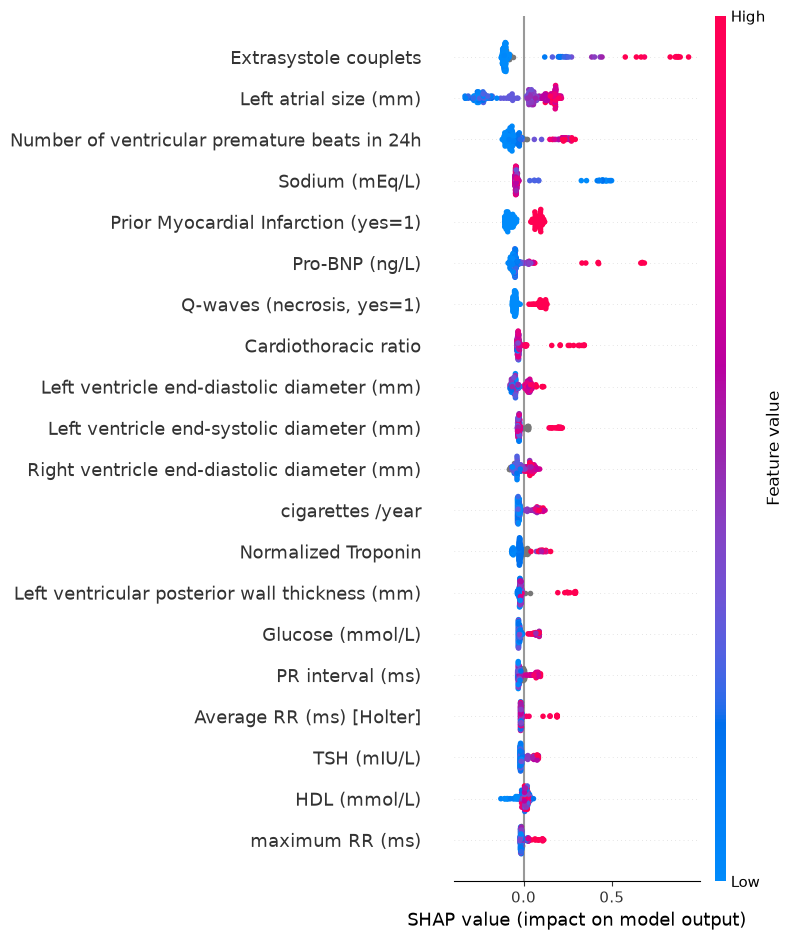

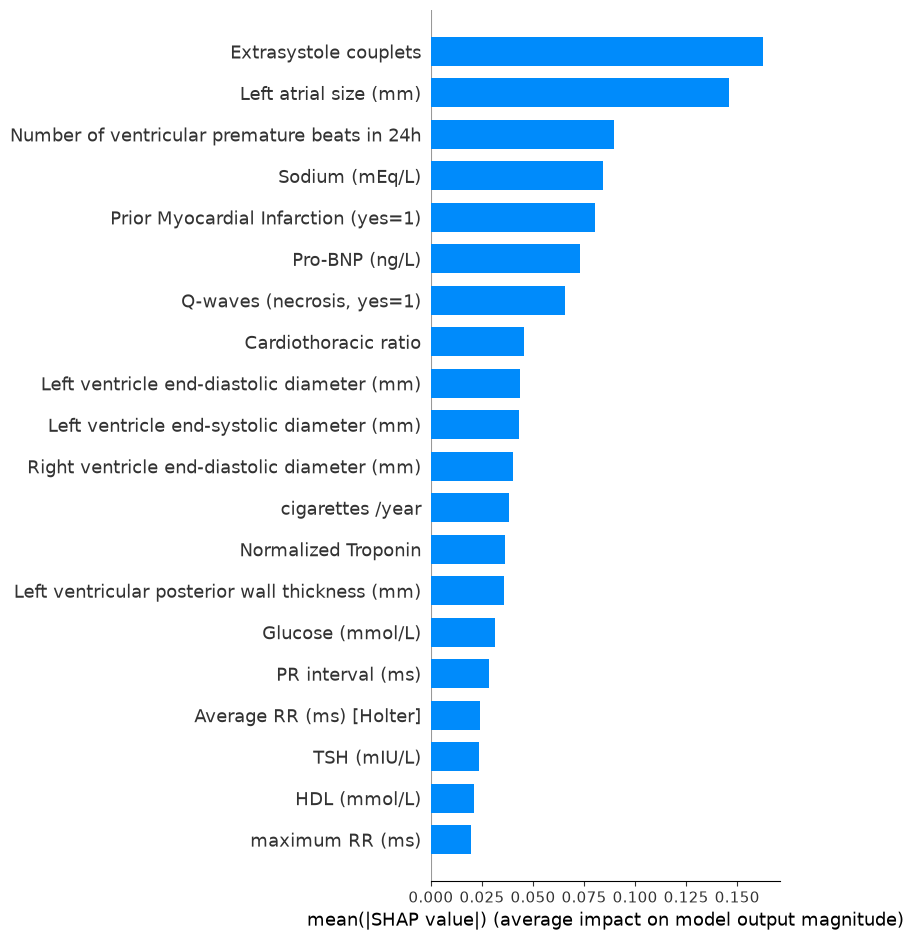

Extrasystole couplets                             0.1628
Left atrial size (mm)                             0.1462
Number of ventricular premature beats in 24h      0.0899
Sodium (mEq/L)                                    0.0844
Prior Myocardial Infarction (yes=1)               0.0804
Pro-BNP (ng/L)                                    0.0729
Q-waves (necrosis, yes=1)                         0.0656
Cardiothoracic ratio                              0.0456
Left ventricle end-diastolic diameter (mm)        0.0437
Left ventricle end-systolic diameter (mm)         0.0430
Right ventricle end-diastolic diameter (mm)       0.0403
cigarettes /year                                  0.0382
Normalized Troponin                               0.0362
Left ventricular posterior wall thickness (mm)    0.0358
Glucose (mmol/L)                                  0.0316
dtype: float64


In [22]:
import numpy as np
import pandas as pd
import h2o
import shap
import matplotlib.pyplot as plt
from h2o.automl import H2OAutoML

h2o.connect(ip="127.0.0.1", port=54321)   # init()은 멈추니 connect를 쓴다

# 0) 컬럼 이름을 순수 str로 통일 (np.str_가 섞이면 H2O 명령이 깨진다)
X.columns = [str(c) for c in X.columns]
cat_cols = [str(c) for c in cat_cols]

# 1) H2OFrame 변환: 범주형은 enum으로 명시, 라벨은 factor
data = X.copy()
data["label_scd"] = y.values
hf = h2o.H2OFrame(data, column_types={c: "enum" for c in cat_cols})
hf["label_scd"] = hf["label_scd"].asfactor()     # 레벨 0/1, 양성 클래스는 1

# 2) 계층 분할: SCD 비율을 train/test에 똑같이 유지, 시드 고정
split = hf["label_scd"].stratified_split(test_frac=0.2, seed=42)
train, test = hf[split == "train"], hf[split == "test"]
print("train:", train.nrow, "| test:", test.nrow)
print("SCD 비율 train/test:",
      train["label_scd"].as_data_frame()["label_scd"].astype(int).mean().round(3),
      test["label_scd"].as_data_frame()["label_scd"].astype(int).mean().round(3))

# 3) AutoML: 트리 계열만 (SHAP을 predict_contributions로 뽑으려고 StackedEnsemble/DL/GLM 제외)
predictors = [str(c) for c in hf.columns if c != "label_scd"]
aml = H2OAutoML(
    max_models=20,              # 시간 제한 대신 모델 수로 제한해야 재현된다
    max_runtime_secs=900,       # 안전장치
    nfolds=5,
    sort_metric="AUCPR",        # 양성 9.8%라 AUC보다 AUCPR이 불균형에 민감하다
    include_algos=["GBM", "DRF", "XGBoost"],
    seed=42,
)
aml.train(x=predictors, y="label_scd", training_frame=train)
print(aml.leaderboard.head(10))

# 4) 테스트 성능: 학습에 안 쓴 20%로만 한 번 평가
leader = aml.leader
perf = leader.model_performance(test)
print("모델:", leader.model_id)
print("test AUC:", round(perf.auc(), 3), "| test AUCPR:", round(perf.aucpr(), 3),
      "| 무작위 기준 AUCPR(양성비율):", round(float(y.mean()), 3))

# 5) SHAP: h2o의 shap_summary_plot은 이 버전에서 np.str_ 에러가 나서
#    SHAP 값만 받고 그림은 shap 라이브러리로 그린다. 단위는 log-odds
contrib = leader.predict_contributions(test, output_format="compact").as_data_frame()
contrib = contrib.drop(columns=["BiasTerm"])

feat = test[predictors].as_data_frame()          # contrib와 같은 행 순서
assert set(contrib.columns) == set(feat.columns), set(contrib.columns) ^ set(feat.columns)
contrib = contrib[feat.columns]

# 점 색은 값의 크기로 칠하므로 범주형은 임의의 숫자 코드로 바꾼다 (범주형 색은 의미 없음)
feat_num = feat.copy()
for c in cat_cols:
    feat_num[c] = feat_num[c].astype("category").cat.codes.replace(-1, np.nan)
feat_num = feat_num.apply(pd.to_numeric, errors="coerce")

shap.summary_plot(contrib.values, feat_num, max_display=20, show=False)
plt.tight_layout(); plt.show()

shap.summary_plot(contrib.values, feat_num, plot_type="bar", max_display=20, show=False)
plt.tight_layout(); plt.show()

imp = contrib.abs().mean().sort_values(ascending=False)
print(imp.head(15).round(4))

In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score

print(aml.leaderboard.head(10))
print("test AUC:", round(perf.auc(), 3), "| AUCPR:", round(perf.aucpr(), 3),
      "| 무작위 기준 AUCPR:", round(float(y.mean()), 3))

# test가 작아서 점수 하나만 믿으면 위험하다 -> 부트스트랩으로 흔들림 범위를 본다
p1 = leader.predict(test).as_data_frame()["p1"].values
y_test = test["label_scd"].as_data_frame()["label_scd"].astype(int).values
print("test 양성:", int(y_test.sum()), "/", len(y_test))

rng = np.random.default_rng(42)
aucs, aps = [], []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test[i].sum() == 0:
        continue
    aucs.append(roc_auc_score(y_test[i], p1[i]))
    aps.append(average_precision_score(y_test[i], p1[i]))
print("AUC 95% 구간:", np.percentile(aucs, [2.5, 97.5]).round(3))
print("AUCPR 95% 구간:", np.percentile(aps, [2.5, 97.5]).round(3))

model_id                                            aucpr       auc    logloss    mean_per_class_error      rmse        mse
XGBoost_grid_1_AutoML_1_20261019_204157_model_4  0.168535  0.67671    0.30529                 0.376306  0.292808  0.0857366
GBM_grid_1_AutoML_1_20261019_204157_model_1      0.16581   0.652679   0.33353                 0.385166  0.302945  0.0917758
XGBoost_1_AutoML_1_20261019_204157               0.160508  0.632275   0.325741                0.370823  0.299885  0.0899308
GBM_grid_1_AutoML_1_20261019_204157_model_2      0.159265  0.64938    0.320531                0.35671   0.297163  0.088306
XRT_1_AutoML_1_20261019_204157                   0.158604  0.655642   0.313936                0.394372  0.298943  0.0893672
GBM_2_AutoML_1_20261019_204157                   0.155932  0.617576   0.329045                0.39899   0.298886  0.0893326
XGBoost_grid_1_AutoML_1_20261019_204157_model_5  0.150479  0.639028   0.390194                0.375267  0.307389  0.0944881
GBM_grid_

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


AUC 95% 구간: [0.543 0.739]
AUCPR 95% 구간: [0.083 0.25 ]


In [24]:
for v in ["Exit of the study", "Cause of death"]:
    i = codes.index[codes["Variable"].astype(str).str.strip() == v][0]
    print(f"[{v}]")
    print(codes.loc[i:i+4, "Codes"].dropna().to_string(), "\n")


[Exit of the study]
0                             0: survivor; 
1                   1: lost to follow-up;  
2              2: cardiac transplantation; 
3                                3: Death; 
4    According to closing date of the study 

[Cause of death]
5                             0: survivor; 
6                   1: non-cardiac death;  
7                                  3: SCD; 
8                 6-7: Pump-failure death; 
9    According to closing date of the study 



In [25]:
H = 1460  # 4년
scd   = base["label_scd"] == 1
alive = base[cod_col] == 0
other = base[cod_col].isin([1, 6, 7])
t = base[fu]

print("SCD 전체:", scd.sum(), "| 그중 4년 안에 발생:", (scd & (t <= H)).sum())
print("생존 전체:", alive.sum(), "| 그중 추적 4년 미만 (결과 모름):", (alive & (t < H)).sum())
print("다른 원인 사망:", other.sum(), "| 그중 4년 안 사망:", (other & (t <= H)).sum())


SCD 전체: 94 | 그중 4년 안에 발생: 91
생존 전체: 694 | 그중 추적 4년 미만 (결과 모름): 7
다른 원인 사망: 172 | 그중 4년 안 사망: 160


## 컬럼 요약
숫자여야 하는 컬럼이 `object`면 문자열이 섞인 것.

In [ ]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
summary

In [ ]:
print("object 컬럼:", df.select_dtypes(include="object").columns.tolist())

In [ ]:
print(base.groupby("label_scd")[fu].median())

label_scd
0    1833.0
1     479.5
Name: Follow-up period from enrollment (days), dtype: float64


In [ ]:
kw = "cigarette|troponin|RR|extrasystole|couplet"
m = defs.astype(str).apply(lambda r: r.str.contains(kw, case=False).any(), axis=1)
print(defs[m].to_string())

     Variable  Column                                                            Definition
12  RMSSD (ms)     CK                Root mean square of successive RR interval differences
13   pNN50 (%)     CL  Percentage of successive RR intervals that differ by more than 50?ms


## 컬럼 정의 (definitions)

In [ ]:
defs

## 범주형 코드표 (codes)

In [ ]:
codes

## 앞 3행 (세로로 보기)

In [ ]:
df.head(3).T